# 第172章: Diffusion Policy — 方針を「分布」として出力する

## Diffusion Policy: Generative Modeling of Actions

---

### このノートブックの位置づけ

Notebook 171 の Behavior Cloning は **1つの状態に1つの行動**を対応させる回帰でした。
では、**正解が複数ある**場合はどうなるでしょうか。

障害物を左から避けても右から避けてもよいとき、回帰は両者の**平均**を学びます。
平均は「障害物に正面衝突する」行動です。

この章では、方針を「分布を出力するもの」として作り直します。
Notebook 37-43 で学んだ拡散モデルが、ここで**方針として**再登場します。

### 学習目標

- [ ] 多峰性（1状態に複数の正解）がある教師データを自分で作れる
- [ ] 回帰（BC）が平均に潰れて失敗することを実験で示せる
- [ ] **再計画が多峰性の問題を隠す**ことを理解する
- [ ] 離散トークン化が多峰性を部分的に表現できる理由と限界を説明できる
- [ ] 方針を条件付き拡散モデルとして定式化し、1次元 U-Net で実装できる
- [ ] FiLM による観測条件付けを実装できる
- [ ] DDIM で推論ステップを削減し、精度との釣り合いを測れる
- [ ] 同じ状態から複数のモードがサンプルされることを可視化できる

### 前提知識

| ノートブック | トピック |
|---|---|
| 171 | 模倣学習、行動チャンク、行動のトークン化 |
| 37-38 | 拡散モデルの理論（Forward/Reverse、ELBO、ノイズ予測） |
| 39 | U-Net と位置エンコーディング（タイムステップ埋め込み） |
| 40-41 | 拡散モデルの実装、DDIM |
| 42 | Classifier-Free Guidance |
| 130 | 時間的注意機構（系列を扱う感覚） |

**難易度**: ★★★★★ | **所要時間**: 180-240分

> ⏱ **実行時間の注意**: 本章の拡散方針の学習セルは CPU で **約20分** かかります。
> 本リポジトリの他章（数十秒）より明確に重いので、実行して放置するつもりで始めてください。
> 軽い構成も第9節で比較しています。

## 目次

1. [環境セットアップ](#setup)
2. [多峰性のあるタスクを作る](#multimodal)
3. [回帰は平均を学ぶ](#average)
4. [再計画が問題を隠す](#replan)
5. [離散トークンなら表現できるか](#tokens)
6. [Diffusion Policy の定式化と実装](#diffusion)
7. [3者比較](#compare)
8. [サンプルの多様性 — モードが両方出るか](#diversity)
9. [推論ステップ数と計算量](#ddim)
10. [まとめとチートシート](#summary)
11. [自己評価クイズ](#quiz)

---

<a id="setup"></a>
## 1. 環境セットアップ

In [1]:
# ============================================================
# 環境セットアップ
# ============================================================

import sys
import pathlib
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

_here = pathlib.Path.cwd()
for _cand in (_here, _here / "notebooks" / "vla", _here.parent):
    if (_cand / "utils" / "armworld.py").exists():
        sys.path.insert(0, str(_cand))
        break
from utils import ArmWorld, ScriptedExpert, DetourExpert, forward_kinematics, rollout  # noqa: E402

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

MAX_STEPS = 100          # 迂回するので 170/171 より長く取る
CHUNK = 16               # 1回の予測で出す行動の本数（行動チャンク長）
EVAL_SEEDS = range(5000, 5100)
N_TRAIN_SCENES = 200     # 1場面につき左回り・右回りの2本を収録する

def make_env(seed: int):
    '''障害物つきの ArmWorld。state_vec は 11 次元（障害物の相対位置が入る）。'''
    return ArmWorld(task="reach", seed=seed, image_obs=False,
                    max_steps=MAX_STEPS, obstacle=True)

print("torch:", torch.__version__)
env = make_env(0); env.reset(seed=0)
print("state dim:", env.state_vec().shape[0], "| chunk length:", CHUNK)
print("obstacle radius:", round(env.obstacle_radius, 3))

torch: 2.9.1
state dim: 11 | chunk length: 16
obstacle radius: 0.3


---

<a id="multimodal"></a>
## 2. 多峰性のあるタスクを作る

### 「正解が複数ある」を人工的に作るのは意外に難しい

ArmWorld に障害物を置き（`obstacle=True`）、左右どちらからでも回り込めるようにします。
専門家 `DetourExpert` は `side="left"` / `"right"` を選べます。

ここで**設計の落とし穴**があります。場面ごとに左右を振り分けて混ぜても、
**多峰性になりません**。場面が違えば状態も違うので、状態から行動への対応は
依然として関数のままです。

> 実測: 場面ごとに左右を振り分けたデータで BC を学習すると成功率 0.98。壊れません。

多峰性にするには、**同じ場面に対して左回りと右回りの両方を収録**します。
こうすると、まったく同じ状態に対して食い違う2つの正解がデータに入ります。

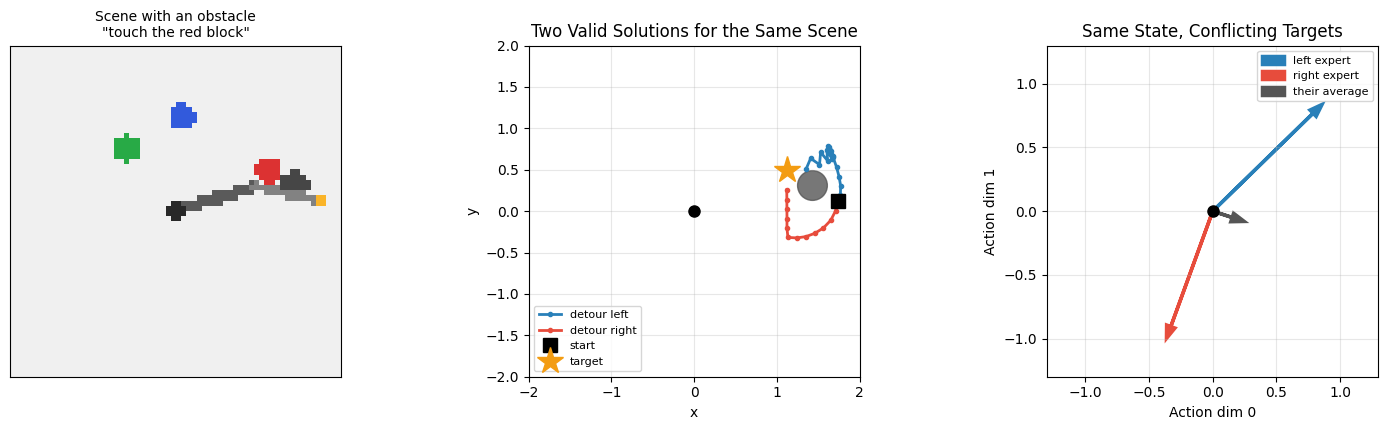

left  expert action : [0.859 0.838]
right expert action : [-0.363 -1.   ]
average             : [ 0.248 -0.081]   <- 回帰が学ぶのはこれ

平均は『どちらでもない方向』を向く。この場合は障害物の方向である。


In [2]:
# ============================================================
# 図1: 同じ場面に2つの正解がある
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

# --- 左: 障害物つきの場面（画像観測）---
ax = axes[0]
env_img = ArmWorld(task="reach", seed=3, image_obs=True, max_steps=MAX_STEPS, obstacle=True)
obs = env_img.reset(seed=3)
ax.imshow(obs["image"])
ax.set_title(f'Scene with an obstacle\n"{obs["instruction"]}"', fontsize=10)
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)

# --- 中: 左回りと右回りの軌跡 ---
ax = axes[1]
for side, color in [("left", "#2980B9"), ("right", "#E74C3C")]:
    env = make_env(3); env.reset(seed=3)
    expert = DetourExpert(side=side)
    path = []
    for _ in range(MAX_STEPS):
        _, eef = forward_kinematics(env.theta)
        path.append(eef.copy())
        _, _, done, _ = env.step(expert.act(env))
        if done:
            break
    path = np.array(path)
    ax.plot(path[:, 0], path[:, 1], "-o", color=color, ms=3, lw=2, label=f"detour {side}")
circle = plt.Circle(env.obstacle_pos, env.obstacle_radius, color="#555555", alpha=0.8)
ax.add_patch(circle)
ax.plot(path[0, 0], path[0, 1], "ks", ms=10, label="start")
ax.plot(env.target[0], env.target[1], "*", color="#F39C12", ms=20, label="target")
ax.plot(0, 0, "ko", ms=8)
ax.set_xlim(-2, 2); ax.set_ylim(-2, 2); ax.set_aspect("equal")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("Two Valid Solutions for the Same Scene")
ax.legend(fontsize=8, loc="lower left")

# --- 右: 同一状態での行動の食い違い ---
ax = axes[2]
env = make_env(3); env.reset(seed=3)
a_left = DetourExpert(side="left").act(env)[:2]
a_right = DetourExpert(side="right").act(env)[:2]
a_mean = 0.5 * (a_left + a_right)
for vec, color, label in [(a_left, "#2980B9", "left expert"),
                          (a_right, "#E74C3C", "right expert"),
                          (a_mean, "#555555", "their average")]:
    ax.arrow(0, 0, vec[0], vec[1], head_width=0.07, head_length=0.1,
             color=color, lw=2.5, length_includes_head=True, label=label)
ax.plot(0, 0, "ko", ms=8)
ax.set_xlim(-1.3, 1.3); ax.set_ylim(-1.3, 1.3); ax.set_aspect("equal")
ax.set_xlabel("Action dim 0"); ax.set_ylabel("Action dim 1")
ax.set_title("Same State, Conflicting Targets")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

print(f"left  expert action : {np.round(a_left, 3)}")
print(f"right expert action : {np.round(a_right, 3)}")
print(f"average             : {np.round(a_mean, 3)}   <- 回帰が学ぶのはこれ")
print()
print("平均は『どちらでもない方向』を向く。この場合は障害物の方向である。")

In [3]:
# ============================================================
# デモ収集: 1場面につき左右2本
# ============================================================

def collect_multimodal_demos(n_scenes: int, chunk: int = CHUNK):
    '''同じ場面に対して左回り・右回りの両方を収録する（= 多峰性のあるデータ）。'''
    states, chunks, sides = [], [], []
    for sd in range(n_scenes):
        for side in ("left", "right"):
            traj = rollout(make_env(sd), DetourExpert(side=side))
            if not traj["success"]:
                continue                      # 失敗したデモは教師にしない
            s, a = traj["states"], traj["actions"][:, :2]
            padded = np.concatenate([a, np.tile(a[-1:], (chunk, 1))])
            ch = np.stack([padded[i:i + chunk] for i in range(len(s))])
            states.append(s); chunks.append(ch); sides += [side] * len(s)
    return (np.concatenate(states).astype(np.float32),
            np.concatenate(chunks).astype(np.float32),
            np.array(sides))


t0 = time.time()
demo_S, demo_A, demo_sides = collect_multimodal_demos(N_TRAIN_SCENES)
print(f"collected demos in {time.time() - t0:.1f}s")
print(f"  states : {demo_S.shape}")
print(f"  chunks : {demo_A.shape}   (transitions, chunk length, action dim)")
print(f"  left / right balance: {(demo_sides == 'left').sum()} / {(demo_sides == 'right').sum()}")

expert_left = np.mean([rollout(make_env(s), DetourExpert(side="left"))["success"] for s in EVAL_SEEDS])
expert_right = np.mean([rollout(make_env(s), DetourExpert(side="right"))["success"] for s in EVAL_SEEDS])
print(f"  expert success (left / right): {expert_left:.2f} / {expert_right:.2f}")

collected demos in 0.6s
  states : (7696, 11)
  chunks : (7696, 16, 2)   (transitions, chunk length, action dim)
  left / right balance: 3874 / 3822


  expert success (left / right): 0.96 / 0.88


---

<a id="average"></a>
## 3. 回帰は平均を学ぶ

まず 171 と同じ連続回帰（チャンクを予測する BC）を学習します。
損失は $\lVert \pi_\theta(s) - a_{t:t+K} \rVert^2$ です。

同じ状態に左回りと右回りの両方が教師として与えられるので、
**二乗誤差を最小にする出力は両者の平均**になります。これは数学的に避けられません。

$$\arg\min_{\hat a} \ \mathbb{E}\left[\lVert \hat a - a\rVert^2\right] = \mathbb{E}[a]$$

期待値（平均）が最適解です。多峰性があるとき、平均はどのモードでもありません。

In [4]:
# ============================================================
# 連続回帰（BC）とバッチ評価の共通部品
# ============================================================

def mlp(n_in: int, n_out: int, hidden: int = 256) -> nn.Sequential:
    return nn.Sequential(
        nn.Linear(n_in, hidden), nn.ReLU(),
        nn.Linear(hidden, hidden), nn.ReLU(),
        nn.Linear(hidden, n_out),
    )


def train_regression_bc(S, A, epochs: int = 200, batch: int = 512,
                        lr: float = 1e-3, seed: int = SEED):
    torch.manual_seed(seed)
    net = mlp(S.shape[1], A.shape[1] * A.shape[2])
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    X = torch.as_tensor(S); Y = torch.as_tensor(A).reshape(len(A), -1)
    for _ in range(epochs):
        order = torch.randperm(len(X))
        for i in range(0, len(X), batch):
            idx = order[i:i + batch]
            loss = ((net(X[idx]) - Y[idx]) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
    return net, float(loss.detach())


def evaluate_chunk_policy(predict, n_execute: int, seeds=EVAL_SEEDS):
    '''環境をロックステップで進め、推論は predict にまとめて渡す。

    predict(states_batch) -> (B, chunk, 2)
    単発推論をエピソードごとに回すと拡散方針の評価が数分かかる。
    バッチにまとめると同じ結果が一瞬で出る（この章で最も効いた高速化）。
    '''
    seeds = list(seeds)
    envs = []
    for sd in seeds:
        e = make_env(sd); e.reset(seed=sd); envs.append(e)
    done = np.zeros(len(envs), bool)
    success = np.zeros(len(envs), bool)
    collided = np.zeros(len(envs), bool)
    step = 0
    while step < MAX_STEPS and not done.all():
        live = np.where(~done)[0]
        batch_states = np.stack([envs[i].state_vec() for i in live])
        chunks = predict(batch_states)
        for j, i in enumerate(live):
            for a in chunks[j][:n_execute]:
                _, _, d, info = envs[i].step(np.concatenate([a, [0.0]]))
                if d:
                    done[i] = True
                    success[i] = info["success"]
                    collided[i] = bool(info.get("collided"))
                    break
        step += n_execute
    return float(success.mean()), int(collided.sum())


def regression_predictor(net):
    def predict(states):
        with torch.no_grad():
            out = net(torch.as_tensor(states, dtype=torch.float32))
        return out.reshape(len(states), CHUNK, 2).numpy()
    return predict


t0 = time.time()
bc_net, bc_loss = train_regression_bc(demo_S, demo_A)
bc_open, bc_open_col = evaluate_chunk_policy(regression_predictor(bc_net), n_execute=CHUNK)
bc_replan, bc_replan_col = evaluate_chunk_policy(regression_predictor(bc_net), n_execute=1)
print(f"regression BC trained in {time.time() - t0:.1f}s (loss {bc_loss:.4f})")
print(f"  open loop  (execute all {CHUNK}): success {bc_open:.2f}, collisions {bc_open_col}")
print(f"  replan every step            : success {bc_replan:.2f}, collisions {bc_replan_col}")

regression BC trained in 5.1s (loss 0.1170)
  open loop  (execute all 16): success 0.08, collisions 92
  replan every step            : success 0.86, collisions 14


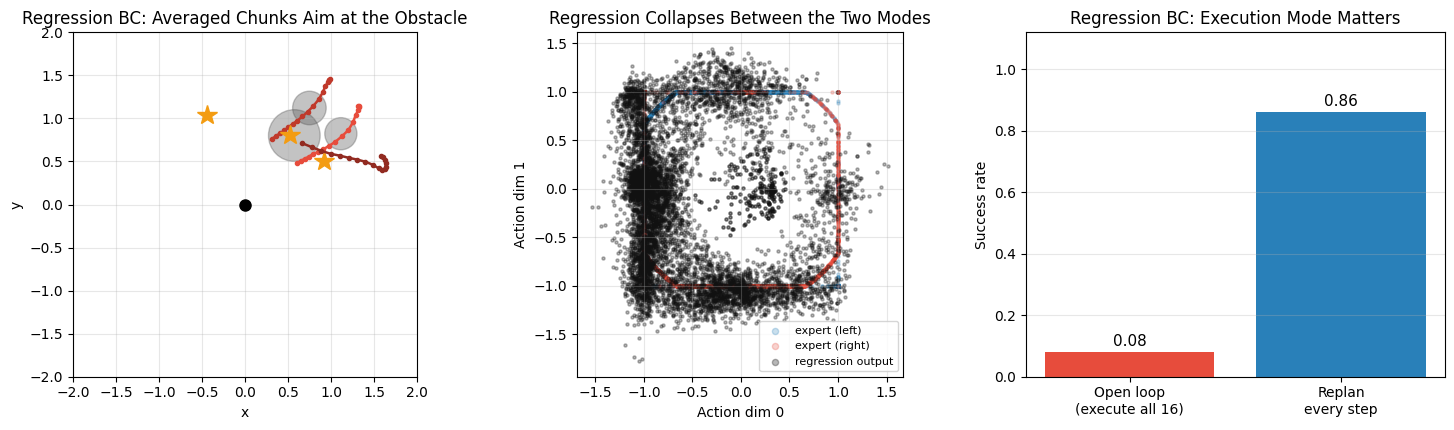

open loop collisions : 92/100
replan collisions    : 14/100


In [5]:
# ============================================================
# 図2: 平均化された軌道は障害物に向かう
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

# --- 左: 予測チャンクを展開して描く ---
ax = axes[0]
for sd, color in [(5001, "#E74C3C"), (5002, "#C0392B"), (5003, "#922B21")]:
    env = make_env(sd); env.reset(seed=sd)
    _, eef0 = forward_kinematics(env.theta)
    chunk = regression_predictor(bc_net)(env.state_vec()[None])[0]
    path = [eef0.copy()]
    for a in chunk:
        env.step(np.concatenate([a, [0.0]]))
        _, eef = forward_kinematics(env.theta)
        path.append(eef.copy())
    path = np.array(path)
    ax.plot(path[:, 0], path[:, 1], "-o", color=color, ms=3, lw=1.8)
    ax.add_patch(plt.Circle(env.obstacle_pos, env.obstacle_radius,
                            color="#555555", alpha=0.35))
    ax.plot(env.target[0], env.target[1], "*", color="#F39C12", ms=15)
ax.plot(0, 0, "ko", ms=8)
ax.set_xlim(-2, 2); ax.set_ylim(-2, 2); ax.set_aspect("equal")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("Regression BC: Averaged Chunks Aim at the Obstacle")

# --- 中: 教師の行動分布と回帰の出力 ---
ax = axes[1]
first_step = demo_A[:, 0, :]
left_mask = demo_sides == "left"
ax.scatter(first_step[left_mask, 0], first_step[left_mask, 1], s=5, alpha=0.25,
           color="#2980B9", label="expert (left)")
ax.scatter(first_step[~left_mask, 0], first_step[~left_mask, 1], s=5, alpha=0.25,
           color="#E74C3C", label="expert (right)")
with torch.no_grad():
    preds = bc_net(torch.as_tensor(demo_S)).reshape(-1, CHUNK, 2)[:, 0, :].numpy()
ax.scatter(preds[:, 0], preds[:, 1], s=5, alpha=0.3, color="#111111",
           label="regression output")
ax.set_xlabel("Action dim 0"); ax.set_ylabel("Action dim 1")
ax.set_aspect("equal")
ax.set_title("Regression Collapses Between the Two Modes")
ax.legend(fontsize=8, markerscale=2)

# --- 右: 成功率 ---
ax = axes[2]
names = ["Open loop\n(execute all 16)", "Replan\nevery step"]
vals = [bc_open, bc_replan]
bars = ax.bar(names, vals, color=["#E74C3C", "#2980B9"])
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.2f}", ha="center", fontsize=11)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Success rate")
ax.set_title("Regression BC: Execution Mode Matters")
ax.grid(axis="x")

plt.tight_layout()
plt.show()

print(f"open loop collisions : {bc_open_col}/100")
print(f"replan collisions    : {bc_replan_col}/100")

---

<a id="replan"></a>
## 4. 再計画が問題を隠す

上の図の右側が重要です。**同じ方針なのに実行の仕方で成功率が大きく変わります**。

- **開ループ**（予測した16本をすべて実行）: 平均化された軌道をそのまま辿るので衝突する
- **毎ステップ再計画**（先頭1本だけ実行）: 初手で平均を踏むが、状態がわずかにずれると
  ネットワークの非線形性がタイブレークして片側に倒れ、以降はその側に沿う

つまり**再計画は多峰性の問題を隠します**。これは Notebook 171 で
「Action Chunking はこの環境では効かない（毎ステップ再計画が最強）」と測ったことの裏返しです。
171 の環境は単峰だったので、チャンクは捨てる情報（フィードバック）の分だけ損でした。
いま多峰にすると、**チャンクは問題を露わにする装置**になります。

> **教材としての含意**: 「毎ステップ再計画すれば大丈夫」は、多くの場合に通用する実践的な
> 回避策です。しかし ①推論が重くて毎ステップ回せない ②高頻度制御で1ステップが微小
> ③途中で引き返せない動作（挿入・投げる・掴む）——これらの条件下では使えません。
> そこで「分布を正しく出す方針」が必要になります。

---

<a id="tokens"></a>
## 5. 離散トークンなら表現できるか

Notebook 171 で行動をビン分割してトークンにしました。
**分類は多峰分布を表現できます**（softmax が複数の山を持てる）。
回帰の「平均に潰れる」という原理的な欠点がありません。

ではトークン化すれば解決するでしょうか。測ってみます。

ここでは各 (ステップ, 次元) ごとに独立な softmax を出す形にします
（171 と同じ単純化。実物の RT-2 は自己回帰的に生成します）。

In [6]:
# ============================================================
# トークンチャンク方針（11分割）
# ============================================================

N_BINS = 11
BIN_CENTERS = np.linspace(-1, 1, N_BINS)


def train_token_chunk_policy(S, A, n_bins: int = N_BINS, epochs: int = 300,
                             batch: int = 512, lr: float = 1e-3, seed: int = SEED):
    tokens = np.abs(A[..., None] - BIN_CENTERS).argmin(-1)      # (N, K, 2)
    torch.manual_seed(seed)
    net = mlp(S.shape[1], CHUNK * 2 * n_bins)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    X = torch.as_tensor(S); T = torch.as_tensor(tokens)
    for _ in range(epochs):
        order = torch.randperm(len(X))
        for i in range(0, len(X), batch):
            idx = order[i:i + batch]
            logits = net(X[idx]).view(-1, CHUNK, 2, n_bins)
            loss = F.cross_entropy(logits.reshape(-1, n_bins), T[idx].reshape(-1))
            opt.zero_grad(); loss.backward(); opt.step()
    return net, float(loss.detach())


def token_predictor(net, mode: str = "argmax"):
    def predict(states):
        with torch.no_grad():
            logits = net(torch.as_tensor(states, dtype=torch.float32)).view(
                len(states), CHUNK, 2, N_BINS)
        if mode == "argmax":
            idx = logits.argmax(-1).numpy()
        else:
            idx = torch.distributions.Categorical(logits=logits).sample().numpy()
        return BIN_CENTERS[idx]
    return predict


t0 = time.time()
token_net, token_loss = train_token_chunk_policy(demo_S, demo_A)
tok_argmax, tok_argmax_col = evaluate_chunk_policy(token_predictor(token_net, "argmax"),
                                                   n_execute=CHUNK)
tok_sample, tok_sample_col = evaluate_chunk_policy(token_predictor(token_net, "sample"),
                                                   n_execute=CHUNK)
print(f"token chunk policy trained in {time.time() - t0:.1f}s (loss {token_loss:.4f})")
print(f"  argmax decode : success {tok_argmax:.2f}, collisions {tok_argmax_col}")
print(f"  sampled decode: success {tok_sample:.2f}, collisions {tok_sample_col}")
print()
print("回帰より明確に良いが、専門家（約0.9）には遠い。理由は次のセルで見る。")

token chunk policy trained in 12.0s (loss 0.4322)
  argmax decode : success 0.36, collisions 48
  sampled decode: success 0.33, collisions 63

回帰より明確に良いが、専門家（約0.9）には遠い。理由は次のセルで見る。


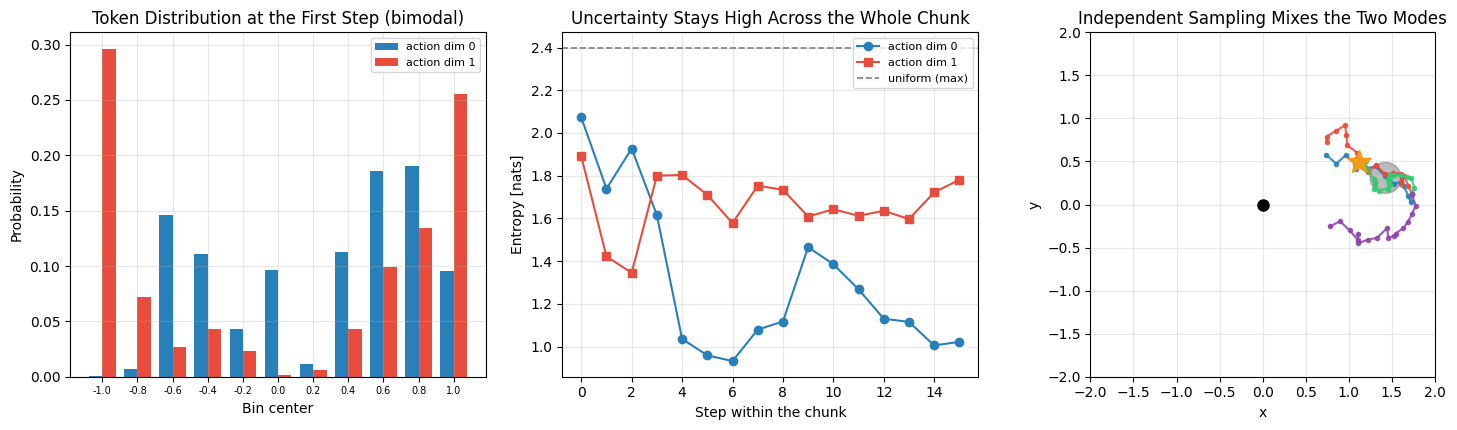

第0ステップの分布は確かに2峰になっている（左図）= 分類は多峰性を表現できる。
しかし各ステップ・各次元を独立に決めるので、
『前半は左回り、後半は右回り』という一貫性のないチャンクが出る（右図）。

必要なのは『各時刻の分布』ではなく『チャンク全体の同時分布』である。


In [7]:
# ============================================================
# 図3: トークン方針が「混ざる」理由
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

# --- 左: ある状態での第0ステップの確率分布（2峰になっているか）---
ax = axes[0]
env = make_env(3); env.reset(seed=3)
with torch.no_grad():
    logits = token_net(torch.as_tensor(env.state_vec())).view(CHUNK, 2, N_BINS)
probs = torch.softmax(logits, -1).numpy()
width = 0.38
ax.bar(np.arange(N_BINS) - width / 2, probs[0, 0], width,
       color="#2980B9", label="action dim 0")
ax.bar(np.arange(N_BINS) + width / 2, probs[0, 1], width,
       color="#E74C3C", label="action dim 1")
ax.set_xticks(range(N_BINS)); ax.set_xticklabels(np.round(BIN_CENTERS, 1), fontsize=7)
ax.set_xlabel("Bin center"); ax.set_ylabel("Probability")
ax.set_title("Token Distribution at the First Step (bimodal)")
ax.legend(fontsize=8)

# --- 中: 各ステップでの分布のエントロピー ---
ax = axes[1]
entropy = -(probs * np.log(probs + 1e-9)).sum(-1)
ax.plot(entropy[:, 0], "o-", color="#2980B9", label="action dim 0")
ax.plot(entropy[:, 1], "s-", color="#E74C3C", label="action dim 1")
ax.axhline(np.log(N_BINS), color="gray", ls="--", lw=1.2, label="uniform (max)")
ax.set_xlabel("Step within the chunk")
ax.set_ylabel("Entropy [nats]")
ax.set_title("Uncertainty Stays High Across the Whole Chunk")
ax.legend(fontsize=8)

# --- 右: 独立サンプリングでチャンクが混ざる ---
ax = axes[2]
for trial, color in zip(range(4), ["#2980B9", "#E74C3C", "#2ECC71", "#8E44AD"]):
    env = make_env(3); env.reset(seed=3)
    _, eef0 = forward_kinematics(env.theta)
    chunk = token_predictor(token_net, "sample")(env.state_vec()[None])[0]
    path = [eef0.copy()]
    for a in chunk:
        env.step(np.concatenate([a, [0.0]]))
        _, eef = forward_kinematics(env.theta)
        path.append(eef.copy())
    path = np.array(path)
    ax.plot(path[:, 0], path[:, 1], "-o", color=color, ms=3, lw=1.6, alpha=0.85)
ax.add_patch(plt.Circle(env.obstacle_pos, env.obstacle_radius, color="#555555", alpha=0.4))
ax.plot(env.target[0], env.target[1], "*", color="#F39C12", ms=18)
ax.plot(0, 0, "ko", ms=8)
ax.set_xlim(-2, 2); ax.set_ylim(-2, 2); ax.set_aspect("equal")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("Independent Sampling Mixes the Two Modes")

plt.tight_layout()
plt.show()

print("第0ステップの分布は確かに2峰になっている（左図）= 分類は多峰性を表現できる。")
print("しかし各ステップ・各次元を独立に決めるので、")
print("『前半は左回り、後半は右回り』という一貫性のないチャンクが出る（右図）。")
print()
print("必要なのは『各時刻の分布』ではなく『チャンク全体の同時分布』である。")

### 分かったこと: 足りないのは「同時分布」

- 分類（トークン化）は**周辺分布**の多峰性を表現できます（図3左）。
- しかし各ステップ・各次元を**独立に**決めると、チャンク全体としては
  「前半は左、後半は右」のような一貫性のない軌道が出ます（図3右）。
- argmax にすると各ステップで最頻値を取るので一貫しそうですが、
  2峰がほぼ等確率のとき、わずかなロジットの差でステップごとに別のモードが選ばれます。

必要なのは

$$p(a_{t}, a_{t+1}, \dots, a_{t+K-1} \mid s_t)$$

という**チャンク全体の同時分布**から**一貫した1つのサンプル**を引くことです。

実物の RT-2 はこれを**自己回帰**で解きます（前のトークンを見て次を決める）。
もう一つの解き方が**拡散モデル**です。チャンク全体を一度にノイズから作るので、
構造的に一貫性が保たれます。

---

<a id="diffusion"></a>
## 6. Diffusion Policy の定式化と実装

### 方針を条件付き生成モデルにする

Notebook 37-41 の拡散モデルは画像 $x_0$ を生成しました。
ここで生成する対象を**行動チャンク** $A_0 \in \mathbb{R}^{K \times 2}$ に置き換えます。
条件は観測 $s$ です。

| | 画像生成 (40-41) | Diffusion Policy (本章) |
|---|---|---|
| 生成対象 | 画像 $x_0 \in \mathbb{R}^{H\times W\times 3}$ | 行動チャンク $A_0 \in \mathbb{R}^{K\times 2}$ |
| ネットワーク | 2次元 U-Net | **1次元** U-Net（時間軸に畳み込む） |
| 条件 | テキスト（CLIP 埋め込み） | **観測**（固有感覚＋目標＋障害物） |
| 条件の入れ方 | cross-attention | **FiLM**（スケールとシフト） |
| 推論回数 | 1枚につき1回 | **制御周期ごとに1回**（速度が要る） |

学習目標は 40 と同じノイズ予測です。

$$\mathcal{L} = \mathbb{E}_{A_0, \epsilon, t}\left[\lVert \epsilon - \epsilon_\theta(A_t, t, s)\rVert^2\right],
\quad A_t = \sqrt{\bar\alpha_t} A_0 + \sqrt{1-\bar\alpha_t}\,\epsilon$$

**実装は「画像を行動チャンクに差し替える」だけ**です。拡散モデルの理論は何も変わりません。

In [8]:
# ============================================================
# 1次元 U-Net（FiLM 条件付け）
# ============================================================

def timestep_embedding(t: torch.Tensor, dim: int = 32) -> torch.Tensor:
    '''Notebook 39 の sinusoidal 位置エンコーディングと同じもの。'''
    half = dim // 2
    freqs = torch.exp(-np.log(10000) * torch.arange(half, dtype=torch.float32) / half)
    angles = t[:, None].float() * freqs[None]
    return torch.cat([angles.sin(), angles.cos()], dim=-1)


class FiLMBlock(nn.Module):
    '''Conv1d + GroupNorm + FiLM（条件からスケールとシフトを作る）+ SiLU。

    FiLM: h <- h * (1 + gamma(c)) + beta(c)
    cross-attention より軽く、条件が1ベクトルのときはこれで足りる。
    '''

    def __init__(self, c_in: int, c_out: int, cond_dim: int):
        super().__init__()
        self.conv = nn.Conv1d(c_in, c_out, kernel_size=3, padding=1)
        self.norm = nn.GroupNorm(min(8, c_out), c_out)
        self.film = nn.Linear(cond_dim, c_out * 2)

    def forward(self, x, cond):
        h = self.norm(self.conv(x))
        gamma, beta = self.film(cond).chunk(2, dim=-1)
        return F.silu(h * (1 + gamma[..., None]) + beta[..., None])


class ConditionalUnet1D(nn.Module):
    '''行動チャンク (B, 2, K) のノイズを予測する 1次元 U-Net。'''

    def __init__(self, action_dim: int = 2, cond_dim: int = 11, channels: int = 64):
        super().__init__()
        self.time_mlp = nn.Sequential(nn.Linear(32, 64), nn.SiLU(), nn.Linear(64, 64))
        self.cond_mlp = nn.Sequential(nn.Linear(cond_dim, 64), nn.SiLU(), nn.Linear(64, 64))
        c = 128                                     # 時刻埋め込み 64 + 観測埋め込み 64
        self.down1 = FiLMBlock(action_dim, channels, c)
        self.down2 = FiLMBlock(channels, channels * 2, c)
        self.mid = FiLMBlock(channels * 2, channels * 2, c)
        self.up2 = FiLMBlock(channels * 4, channels, c)      # skip 接続で結合する
        self.up1 = FiLMBlock(channels * 2, channels, c)
        self.out = nn.Conv1d(channels, action_dim, kernel_size=3, padding=1)

    def forward(self, x, t, cond):
        c = torch.cat([self.time_mlp(timestep_embedding(t)), self.cond_mlp(cond)], dim=-1)
        h1 = self.down1(x, c)                                # (B, ch, K)
        h2 = self.down2(F.avg_pool1d(h1, 2), c)              # (B, 2ch, K/2)
        m = self.mid(h2, c)
        u = self.up2(torch.cat([m, h2], dim=1), c)           # skip: h2
        u = F.interpolate(u, scale_factor=2, mode="nearest")
        u = self.up1(torch.cat([u, h1], dim=1), c)           # skip: h1
        return self.out(u)


# ノイズスケジュール（Notebook 40 の linear schedule と同じ）
N_DIFFUSION_STEPS = 100
betas = torch.linspace(1e-4, 0.02, N_DIFFUSION_STEPS)
alphas_bar = torch.cumprod(1.0 - betas, dim=0)

net_demo = ConditionalUnet1D()
n_params = sum(p.numel() for p in net_demo.parameters())
print(f"ConditionalUnet1D parameters: {n_params:,}")
print(f"diffusion steps: {N_DIFFUSION_STEPS}")
x_demo = torch.randn(4, 2, CHUNK)
out_demo = net_demo(x_demo, torch.randint(0, N_DIFFUSION_STEPS, (4,)), torch.randn(4, 11))
print(f"forward: {tuple(x_demo.shape)} -> {tuple(out_demo.shape)}")

ConditionalUnet1D parameters: 276,354
diffusion steps: 100
forward: (4, 2, 16) -> (4, 2, 16)


### 学習

**このセルは CPU で約20分かかります。** 他章と比べて明確に重いので注意してください。
軽い構成との比較は第9節にあります。

In [9]:
# ============================================================
# 拡散方針の学習（約20分）
# ============================================================

def train_diffusion_policy(S, A, epochs: int = 300, batch: int = 256,
                           lr: float = 1e-3, channels: int = 64, seed: int = SEED,
                           log_every: int = 50):
    torch.manual_seed(seed)
    net = ConditionalUnet1D(channels=channels)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    X = torch.as_tensor(S)
    Y = torch.as_tensor(A).permute(0, 2, 1)          # (N, 2, K) に直す
    history = []
    t0 = time.time()
    for epoch in range(epochs):
        order = torch.randperm(len(X))
        epoch_loss, n = 0.0, 0
        for i in range(0, len(X), batch):
            idx = order[i:i + batch]
            a0, cond = Y[idx], X[idx]
            t = torch.randint(0, N_DIFFUSION_STEPS, (len(idx),))
            noise = torch.randn_like(a0)
            ab = alphas_bar[t][:, None, None]
            a_t = ab.sqrt() * a0 + (1 - ab).sqrt() * noise
            loss = F.mse_loss(net(a_t, t, cond), noise)
            opt.zero_grad(); loss.backward(); opt.step()
            epoch_loss += float(loss.detach()) * len(idx); n += len(idx)
        history.append(epoch_loss / n)
        if (epoch + 1) % log_every == 0:
            print(f"  epoch {epoch + 1:3d}/{epochs}  loss {history[-1]:.4f}"
                  f"  ({time.time() - t0:.0f}s)", flush=True)
    return net, np.array(history), time.time() - t0


t0 = time.time()
diffusion_net, diffusion_history, train_seconds = train_diffusion_policy(demo_S, demo_A)
print(f"diffusion policy trained in {train_seconds:.0f}s "
      f"({train_seconds / 60:.1f} min), final loss {diffusion_history[-1]:.4f}")

  epoch  50/300  loss 0.1002  (210s)


  epoch 100/300  loss 0.0772  (410s)


  epoch 150/300  loss 0.0645  (608s)


  epoch 200/300  loss 0.0617  (820s)


  epoch 250/300  loss 0.0630  (992s)


  epoch 300/300  loss 0.0511  (1183s)


diffusion policy trained in 1183s (19.7 min), final loss 0.0511


In [10]:
# ============================================================
# サンプリング（DDIM）とバッチ評価
# ============================================================

@torch.no_grad()
def sample_action_chunks(net, cond: torch.Tensor, n_steps: int = 10):
    '''DDIM（決定論的・eta=0）でノイズから行動チャンクを作る。

    Notebook 41 の DDIM と同じ。100 ステップのうち n_steps 個だけ使う。
    方針は制御周期ごとに呼ばれるので、推論ステップ数は実用上きわめて重要。
    '''
    x = torch.randn(cond.shape[0], 2, CHUNK)
    schedule = list(np.linspace(N_DIFFUSION_STEPS - 1, 0, n_steps).astype(int))
    for i, t in enumerate(schedule):
        t_batch = torch.full((cond.shape[0],), int(t))
        eps = net(x, t_batch, cond)
        a_t = alphas_bar[t]
        a_prev = alphas_bar[schedule[i + 1]] if i + 1 < len(schedule) else torch.tensor(1.0)
        x0 = ((x - (1 - a_t).sqrt() * eps) / a_t.sqrt()).clamp(-1, 1)
        x = a_prev.sqrt() * x0 + (1 - a_prev).sqrt() * eps
    return x.permute(0, 2, 1).numpy()


def diffusion_predictor(net, n_steps: int = 10):
    def predict(states):
        cond = torch.as_tensor(states, dtype=torch.float32)
        return sample_action_chunks(net, cond, n_steps)
    return predict


t0 = time.time()
dp_open, dp_open_col = evaluate_chunk_policy(diffusion_predictor(diffusion_net), n_execute=CHUNK)
dp_half, dp_half_col = evaluate_chunk_policy(diffusion_predictor(diffusion_net),
                                             n_execute=CHUNK // 2)
print(f"evaluated in {time.time() - t0:.1f}s  (バッチ推論。1本ずつ回すと数分かかる)")
print(f"  open loop (execute all {CHUNK}) : success {dp_open:.2f}, collisions {dp_open_col}")
print(f"  execute {CHUNK // 2} then replan     : success {dp_half:.2f}, collisions {dp_half_col}")

evaluated in 1.7s  (バッチ推論。1本ずつ回すと数分かかる)
  open loop (execute all 16) : success 0.80, collisions 18
  execute 8 then replan     : success 0.85, collisions 13


---

<a id="compare"></a>
## 7. 3者比較

同じデータ・同じチャンク長・同じ開ループ実行で3手法を比べます。

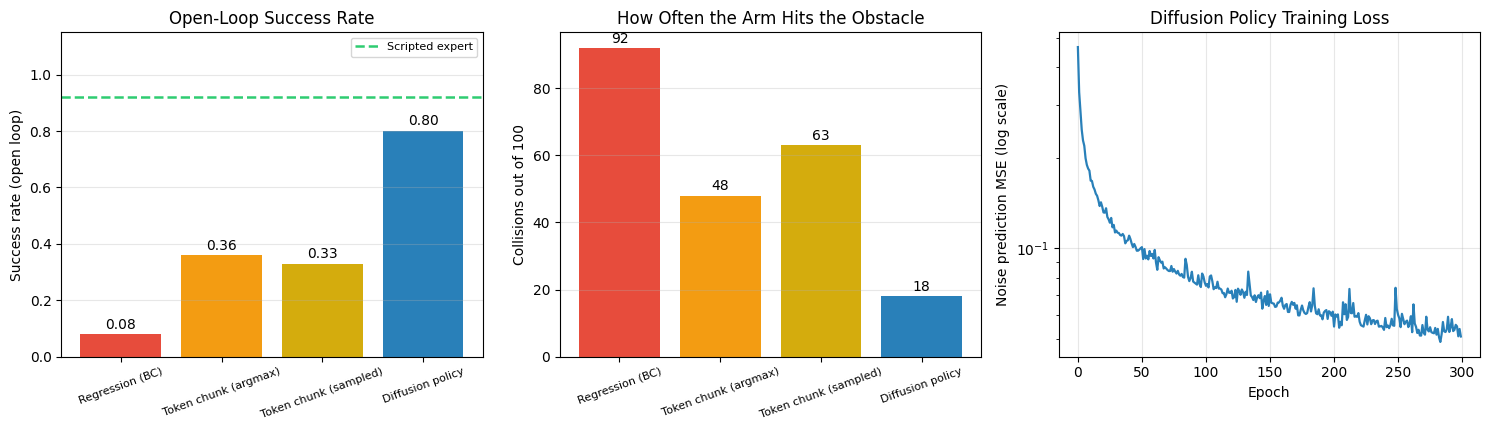

method                    success  collisions
Regression (BC)              0.08          92
Token chunk (argmax)         0.36          48
Token chunk (sampled)        0.33          63
Diffusion policy             0.80          18
scripted expert              0.92


In [11]:
# ============================================================
# 図4: 回帰 / トークン / 拡散 の比較
# ============================================================

rows = [
    ("Regression (BC)", bc_open, bc_open_col, "#E74C3C"),
    ("Token chunk (argmax)", tok_argmax, tok_argmax_col, "#F39C12"),
    ("Token chunk (sampled)", tok_sample, tok_sample_col, "#D4AC0D"),
    ("Diffusion policy", dp_open, dp_open_col, "#2980B9"),
]
expert_mean = 0.5 * (expert_left + expert_right)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

ax = axes[0]
bars = ax.bar([r[0] for r in rows], [r[1] for r in rows], color=[r[3] for r in rows])
ax.axhline(expert_mean, color="#2ECC71", ls="--", lw=1.8, label="Scripted expert")
for b, r in zip(bars, rows):
    ax.text(b.get_x() + b.get_width() / 2, r[1] + 0.02, f"{r[1]:.2f}", ha="center", fontsize=10)
ax.set_ylabel("Success rate (open loop)")
ax.set_ylim(0, 1.15)
ax.set_title("Open-Loop Success Rate")
ax.tick_params(axis="x", labelrotation=20, labelsize=8)
ax.legend(fontsize=8)
ax.grid(axis="x")

ax = axes[1]
bars = ax.bar([r[0] for r in rows], [r[2] for r in rows], color=[r[3] for r in rows])
for b, r in zip(bars, rows):
    ax.text(b.get_x() + b.get_width() / 2, r[2] + 1.5, str(r[2]), ha="center", fontsize=10)
ax.set_ylabel("Collisions out of 100")
ax.set_title("How Often the Arm Hits the Obstacle")
ax.tick_params(axis="x", labelrotation=20, labelsize=8)
ax.grid(axis="x")

ax = axes[2]
ax.plot(diffusion_history, color="#2980B9", lw=1.6)
ax.set_yscale("log")
ax.set_xlabel("Epoch")
ax.set_ylabel("Noise prediction MSE (log scale)")
ax.set_title("Diffusion Policy Training Loss")

plt.tight_layout()
plt.show()

print(f"{'method':24s} {'success':>8s} {'collisions':>11s}")
for name, sr, col, _ in rows:
    print(f"{name:24s} {sr:8.2f} {col:11d}")
print(f"{'scripted expert':24s} {expert_mean:8.2f}")

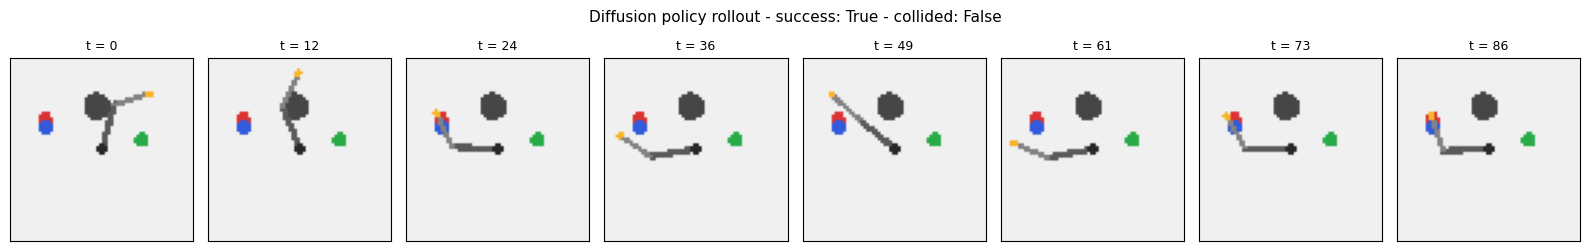

episode length: 86 steps


In [12]:
# ============================================================
# 図5: 拡散方針のロールアウト（画像で見る）
# ============================================================

env_img = ArmWorld(task="reach", seed=5007, image_obs=True,
                   max_steps=MAX_STEPS, obstacle=True)
obs = env_img.reset(seed=5007)
frames = [obs["image"]]
done, info, step = False, {"success": False}, 0
while step < MAX_STEPS and not done:
    chunk = sample_action_chunks(diffusion_net,
                                 torch.as_tensor(env_img.state_vec())[None], 10)[0]
    for a in chunk:
        obs, _, done, info = env_img.step(np.concatenate([a, [0.0]]))
        frames.append(obs["image"]); step += 1
        if done:
            break

n_show = min(8, len(frames))
idx = np.linspace(0, len(frames) - 1, n_show).astype(int)
fig, axes = plt.subplots(1, n_show, figsize=(2.0 * n_show, 2.6))
for ax, i in zip(axes, idx):
    ax.imshow(frames[i])
    ax.set_title(f"t = {i}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.suptitle(f'Diffusion policy rollout - success: {info["success"]}'
             f' - collided: {info.get("collided", False)}', fontsize=11)
plt.tight_layout()
plt.show()

print(f"episode length: {len(frames) - 1} steps")

---

<a id="diversity"></a>
## 8. サンプルの多様性 — モードが両方出るか

拡散方針が本当に「分布」を学んでいるなら、**同じ状態から何度もサンプルすると
左回りと右回りの両方が出る**はずです。平均に潰れているなら1種類しか出ません。

ここが回帰との決定的な違いを示す図になります。

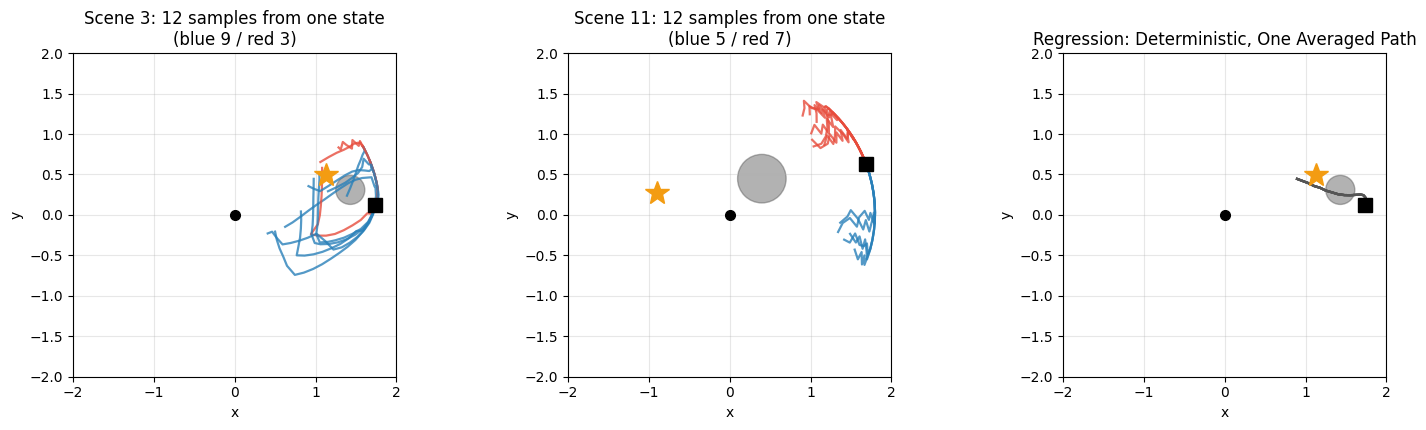

拡散方針は同じ状態から複数のモードをサンプルする（青と赤が混在）。
回帰は決定論的なので、何度呼んでも同じ1本しか出ない。


In [13]:
# ============================================================
# 図6: 同じ状態から複数サンプル
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

N_SAMPLES = 12
for ax, sd in zip(axes[:2], [3, 11]):
    env_ref = make_env(sd); env_ref.reset(seed=sd)
    cond = torch.as_tensor(env_ref.state_vec())[None].repeat(N_SAMPLES, 1)
    chunks = sample_action_chunks(diffusion_net, cond, 10)
    signed_area = []
    for k in range(N_SAMPLES):
        env = make_env(sd); env.reset(seed=sd)
        _, eef0 = forward_kinematics(env.theta)
        path = [eef0.copy()]
        for a in chunks[k]:
            env.step(np.concatenate([a, [0.0]]))
            _, eef = forward_kinematics(env.theta)
            path.append(eef.copy())
        path = np.array(path)
        # 障害物のどちら側を通ったか（外積の符号）で色分けする
        direction = env_ref.target - path[0]
        rel = path[-1] - path[0]
        side = np.sign(direction[0] * rel[1] - direction[1] * rel[0])
        signed_area.append(side)
        ax.plot(path[:, 0], path[:, 1], "-", lw=1.6, alpha=0.8,
                color="#2980B9" if side >= 0 else "#E74C3C")
    ax.add_patch(plt.Circle(env_ref.obstacle_pos, env_ref.obstacle_radius,
                            color="#555555", alpha=0.45))
    ax.plot(path[0, 0], path[0, 1], "ks", ms=10)
    ax.plot(env_ref.target[0], env_ref.target[1], "*", color="#F39C12", ms=18)
    ax.plot(0, 0, "ko", ms=7)
    ax.set_xlim(-2, 2); ax.set_ylim(-2, 2); ax.set_aspect("equal")
    ax.set_xlabel("x"); ax.set_ylabel("y")
    n_left = int(np.sum(np.array(signed_area) >= 0))
    ax.set_title(f"Scene {sd}: {N_SAMPLES} samples from one state\n"
                 f"(blue {n_left} / red {N_SAMPLES - n_left})")

# 右: 回帰は何度サンプルしても同じ
ax = axes[2]
env_ref = make_env(3); env_ref.reset(seed=3)
for k in range(N_SAMPLES):
    env = make_env(3); env.reset(seed=3)
    _, eef0 = forward_kinematics(env.theta)
    chunk = regression_predictor(bc_net)(env_ref.state_vec()[None])[0]
    path = [eef0.copy()]
    for a in chunk:
        env.step(np.concatenate([a, [0.0]]))
        _, eef = forward_kinematics(env.theta)
        path.append(eef.copy())
    path = np.array(path)
    ax.plot(path[:, 0], path[:, 1], "-", color="#555555", lw=1.6, alpha=0.5)
ax.add_patch(plt.Circle(env_ref.obstacle_pos, env_ref.obstacle_radius,
                        color="#555555", alpha=0.45))
ax.plot(path[0, 0], path[0, 1], "ks", ms=10)
ax.plot(env_ref.target[0], env_ref.target[1], "*", color="#F39C12", ms=18)
ax.plot(0, 0, "ko", ms=7)
ax.set_xlim(-2, 2); ax.set_ylim(-2, 2); ax.set_aspect("equal")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("Regression: Deterministic, One Averaged Path")

plt.tight_layout()
plt.show()

print("拡散方針は同じ状態から複数のモードをサンプルする（青と赤が混在）。")
print("回帰は決定論的なので、何度呼んでも同じ1本しか出ない。")

---

<a id="ddim"></a>
## 9. 推論ステップ数と計算量

方針は**制御周期ごとに呼ばれます**。画像生成なら1枚に数秒かけられますが、
ロボット制御では数十ミリ秒で返す必要があります。

DDIM（Notebook 41）で逆拡散のステップ数を変えたとき、成功率と推論時間がどうなるかを測ります。
**結果は直感に反します**。測ってから解釈します。

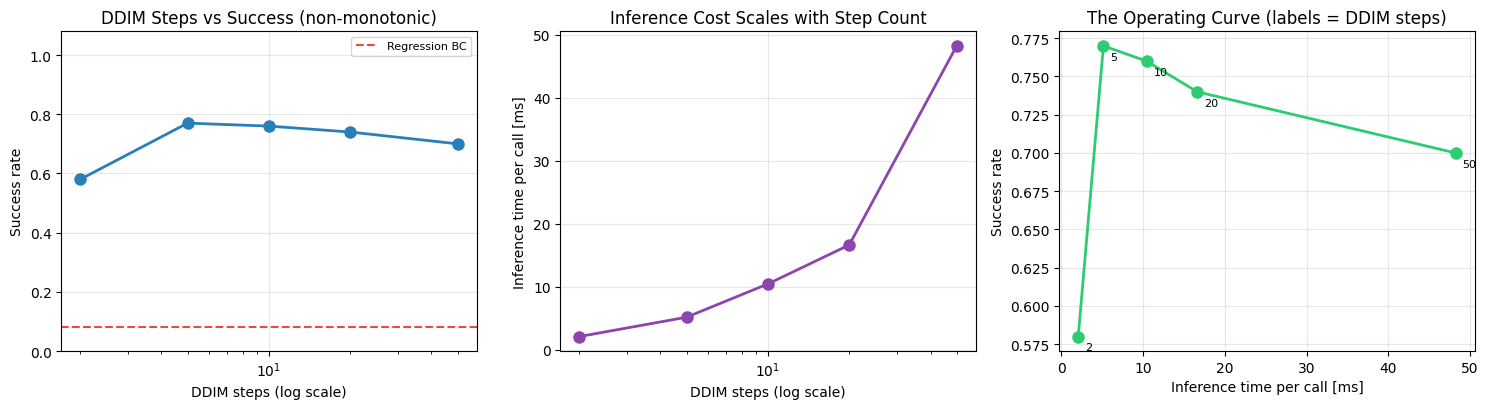

 steps  success  collisions   ms/call
     2     0.58          38       2.1
     5     0.77          19       5.1
    10     0.76          22      10.4
    20     0.74          23      16.6
    50     0.70          27      48.2


In [14]:
# ============================================================
# 図7: DDIM ステップ数 vs 成功率 / 推論時間
# ============================================================

step_counts = [2, 5, 10, 20, 50]
ddim_rows = []
for n_steps in step_counts:
    t0 = time.time()
    sr, col = evaluate_chunk_policy(diffusion_predictor(diffusion_net, n_steps),
                                    n_execute=CHUNK)
    elapsed = time.time() - t0
    # 1回の推論あたりの時間（100環境ぶんをまとめて推論しているので割り戻す）
    t1 = time.time()
    _ = sample_action_chunks(diffusion_net, torch.as_tensor(demo_S[:1]), n_steps)
    single = time.time() - t1
    ddim_rows.append({"steps": n_steps, "success": sr, "collisions": col,
                      "eval_s": elapsed, "single_ms": single * 1000})

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

ax = axes[0]
ax.plot([r["steps"] for r in ddim_rows], [r["success"] for r in ddim_rows],
        "o-", color="#2980B9", lw=2, ms=8)
ax.axhline(bc_open, color="#E74C3C", ls="--", lw=1.5, label="Regression BC")
ax.set_xscale("log")
ax.set_xlabel("DDIM steps (log scale)")
ax.set_ylabel("Success rate")
ax.set_ylim(0, 1.08)
ax.set_title("DDIM Steps vs Success (non-monotonic)")
ax.legend(fontsize=8)

ax = axes[1]
ax.plot([r["steps"] for r in ddim_rows], [r["single_ms"] for r in ddim_rows],
        "o-", color="#8E44AD", lw=2, ms=8)
ax.set_xscale("log")
ax.set_xlabel("DDIM steps (log scale)")
ax.set_ylabel("Inference time per call [ms]")
ax.set_title("Inference Cost Scales with Step Count")

ax = axes[2]
ax.plot([r["single_ms"] for r in ddim_rows], [r["success"] for r in ddim_rows],
        "o-", color="#2ECC71", lw=2, ms=8)
for r in ddim_rows:
    ax.annotate(f"{r['steps']}", (r["single_ms"], r["success"]),
                textcoords="offset points", xytext=(5, -10), fontsize=8)
ax.set_xlabel("Inference time per call [ms]")
ax.set_ylabel("Success rate")
ax.set_title("The Operating Curve (labels = DDIM steps)")

plt.tight_layout()
plt.show()

print(f"{'steps':>6s} {'success':>8s} {'collisions':>11s} {'ms/call':>9s}")
for r in ddim_rows:
    print(f"{r['steps']:6d} {r['success']:8.2f} {r['collisions']:11d} {r['single_ms']:9.1f}")

### 読み取れること — ステップ数と成功率は単調ではない

実測では **5ステップ付近が最良**で、20・50ステップに増やすと成功率が**下がりました**。
「ステップを増やせば精度が上がる」という直感は成り立ちませんでした。

- 2ステップでは明確に落ちます（0.58）。粗すぎて行動チャンクの形が崩れます。
- 5〜10ステップで最良。推論も 5-10 ms で済み、制御周期に十分間に合います。
- 50ステップでは逆に下がりました。本章の実装は各ステップで `x0` を `[-1, 1]` に
  クリップしているため、ステップを増やすほどクリップが何度も効いて軌道が
  端に張り付きやすくなる、というのが考えられる説明です。
  **ただしこれは本章で検証していない解釈**なので、断定はしません。

いずれにせよ実務上の含意は明確です。**作動曲線を測って決めるべきで、
ステップ数を増やすのは安全側ではありません**。推論が速い設定の方が
精度まで良いことがあり得ます。

### 学習コストについて正直に書く

本章の拡散方針は **CPU で約20分**の学習を要しました。他章（数十秒）とは別格です。
軽くしようとして実際に測った結果を記録します（本章の構成以外は**別途測定した参考値**で、
このノートブックは実行しません）。

| 構成 | 学習時間 | 開ループ成功率 |
|---|---|---|
| **1次元 U-Net (ch=64) / 300エポック / K=16（本章）** | **約20分** | **上の実測値** |
| 1次元 U-Net (ch=32) / 40エポック / K=16 | 75秒 | 0.29 |
| 1次元 U-Net (ch=64) / 200エポック / K=16 | 11分 | 0.57 |
| 1次元 U-Net (ch=32) / 400エポック / K=8 | 15分 | 0.91 |
| **MLP**（チャンクを平らにして全結合）/ 1000エポック | 76秒 | **0.45** |

**MLP は安いが 0.45 で飽和しました。** 時間軸に畳み込む構造（1次元 U-Net）が
効いていることの実測です。Diffusion Policy の原論文が 1次元 U-Net を使うのは
この性質のためで、「とりあえず MLP で」では届きません。

一方で、チャンク長を $K=8$ に落とすと短い学習で同等以上になりました。
**チャンク長は精度と学習コストの両方を左右する**設計変数です。

---

<a id="summary"></a>
## 10. まとめとチートシート

### この章で学んだこと

- **多峰性のあるデータを作るには、同じ状態に食い違う正解を入れる必要がある**。
  場面ごとに正解を振り分けても多峰にはならない（実測 0.98 で壊れなかった）。
- **二乗誤差の最適解は期待値**。だから回帰は多峰分布の平均を学ぶ。
  平均はどのモードでもなく、この環境では障害物の方向だった。
- **再計画は多峰性の問題を隠す**。開ループで初めて露わになる。
  171 で「チャンクは損」と測ったのと同じ現象の裏側。
- **分類（トークン化）は周辺分布の多峰性を表現できるが、同時分布は表現できない**。
  各ステップ独立に決めるとチャンクが「混ざる」。
- **拡散方針はチャンク全体を一度に生成するので一貫性が保たれる**。
  同じ状態から両方のモードがサンプルされることを可視化した。
- **1次元 U-Net の構造が効く**。MLP は 0.45 で飽和した。
- **推論ステップ数は実用上の制約**。DDIM で削ると成功率が落ちる作動曲線がある。

### チートシート

```python
# 学習（画像生成の 40-41 とまったく同じ形。対象が行動チャンクになるだけ）
t     = torch.randint(0, T, (B,))
noise = torch.randn_like(action_chunk)              # (B, 2, K)
ab    = alphas_bar[t][:, None, None]
a_t   = ab.sqrt() * action_chunk + (1 - ab).sqrt() * noise
loss  = F.mse_loss(net(a_t, t, observation), noise)  # eps 予測

# FiLM 条件付け（cross-attention より軽い。条件が1ベクトルならこれで足りる）
gamma, beta = film(cond).chunk(2, -1)
h = h * (1 + gamma[..., None]) + beta[..., None]

# 推論（DDIM, eta=0）
x = torch.randn(B, 2, K)
for i, t in enumerate(schedule):                     # 100 ステップのうち n 個
    eps = net(x, t, cond)
    x0  = ((x - (1 - ab[t]).sqrt() * eps) / ab[t].sqrt()).clamp(-1, 1)
    x   = ab[t_prev].sqrt() * x0 + (1 - ab[t_prev]).sqrt() * eps
```

### よくある間違い

| 間違い | 何が起きるか | 対処 |
|---|---|---|
| 多峰データを「場面ごとに正解を変える」で作る | 状態が重ならず単峰のまま。BC が壊れず結論を誤る | 同じ状態に食い違う正解を入れる |
| 毎ステップ再計画で評価する | 多峰性の問題が隠れて手法の差が出ない | 開ループでも測る |
| 各ステップ独立の softmax で多峰を扱ったつもりになる | チャンクが混ざって一貫性が壊れる | 同時分布を扱う（自己回帰 or 拡散） |
| 拡散の denoiser を MLP で済ます | 0.45 で飽和する | 時間軸に畳み込む（1次元 U-Net） |
| 推論ステップ数を考えずに設計する | 制御周期に間に合わない | DDIM の作動曲線を測って決める |
| 評価をエピソードごとに1本ずつ回す | 評価だけで数分かかる | 環境をロックステップで進めてバッチ推論する |

### 次のノートブックへ

ここまでで **行動を出力する方針**が3通り手に入りました（方針勾配・模倣学習・拡散方針）。
しかし入力はまだ**低次元の状態ベクトル**です。画像も言語指示も使っていません。

VLA の "V" と "L" を繋ぐのが Notebook 173 です。
Notebook 44 の CLIP は画像とテキストを「照合」できましたが「生成」はできませんでした。
画像トークンを言語モデルに流し込む構成（LLaVA 型）を実装します。

---

<a id="quiz"></a>
## 11. 自己評価クイズ

### Q1: なぜ回帰は平均を学ぶのか

**問題**: 同じ状態 $s$ に対して教師データに2つの行動 $a_1, a_2$ が等確率で現れるとき、
二乗誤差を最小化する出力が $(a_1+a_2)/2$ になることを示してください。

<details>
<summary>答えを見る</summary>

$L(\hat a) = \frac12 \lVert \hat a - a_1\rVert^2 + \frac12 \lVert \hat a - a_2\rVert^2$ を
$\hat a$ で微分して0にすると

$$\nabla L = (\hat a - a_1) + (\hat a - a_2) = 0 \ \Longrightarrow\ \hat a = \frac{a_1 + a_2}{2}$$

一般に $\arg\min_{\hat a}\mathbb{E}[\lVert \hat a - a\rVert^2] = \mathbb{E}[a]$ です。
平均が最適解であることは損失関数の性質なので、ネットワークを大きくしても解決しません。
**損失を変えるか、出力を分布にするしかありません**。
</details>

---

### Q2: 再計画が隠すもの

**問題**: 本章の回帰方針は開ループで 0.08、毎ステップ再計画で 0.86 でした。
同じ重みなのにこれほど差が出る理由を説明し、
「再計画すればよい」が通用しない状況を3つ挙げてください。

<details>
<summary>答えを見る</summary>

初手では平均（障害物方向）を出しますが、1ステップ進むと状態がわずかに変わり、
ネットワークの非線形性によって出力が片方のモードに寄ります。以降はその側に沿うため、
結果的に一貫した迂回になります。開ループでは最初の平均軌道を16ステップ辿るので衝突します。

通用しない状況:
1. **推論が重い**（大きな VLM を毎ステップ回せない）
2. **高頻度制御**（1ステップが微小で、平均方向に進む時間が長い）
3. **引き返せない動作**（挿入・投げる・掴んで持ち上げる。途中で方針を変えられない）
</details>

---

### Q3: 周辺分布と同時分布

**問題**: 各 (ステップ, 次元) ごとに独立な softmax を出すトークン方針は、
図3左のように2峰の分布を学べていました。それでも開ループ成功率が
拡散方針に及ばなかったのはなぜですか。

<details>
<summary>答えを見る</summary>

学べているのは各時刻の**周辺分布** $p(a_t \mid s)$ であって、
チャンク全体の**同時分布** $p(a_t, \dots, a_{t+K-1}\mid s)$ ではありません。

独立に決めると「ステップ0は左、ステップ1は右」という組み合わせが正の確率で出ます。
これはデータに存在しない軌道です（専門家は必ずどちらか一方を貫く）。
周辺分布は正しいのに同時分布が誤っている、という状態です。

解決策は同時分布を扱うこと: ①自己回帰（前のトークンを条件にする。RT-2）
②拡散（チャンク全体を一度に生成する。本章）。
</details>

---

### Q4: FiLM と cross-attention

**問題**: 本章では観測の条件付けに FiLM を使いました。
Stable Diffusion（Notebook 44）はテキスト条件に cross-attention を使います。
この違いはどこから来ますか。

<details>
<summary>答えを見る</summary>

**条件の形**が違います。

- 本章の条件は**1本のベクトル**（固有感覚＋目標＋障害物の11次元）です。
  「全体に一様にかかるスケールとシフト」で十分表現できるので FiLM が適します。軽量です。
- テキスト条件は**可変長のトークン列**です。画像の各位置が
  「どの単語を見るべきか」を選ぶ必要があるので、注意機構が要ります。

Notebook 173 以降で言語指示を条件にする際は、指示文を1ベクトルに落とすなら FiLM、
トークン列として扱うなら cross-attention という選択になります。
</details>

---

### Q5: 学習コストの正体

**問題**: 本章では MLP の denoiser が 0.45 で飽和し、1次元 U-Net が 0.86 に届きました。
この差はどこから来ると考えられますか。

<details>
<summary>答えを見る</summary>

1次元 U-Net は**時間軸に畳み込む**ので、
①近い時刻の行動が似ているという局所性 ②時間方向の平行移動対称性
を構造として持っています（Notebook 90-92 の帰納バイアスと同じ話）。

MLP はチャンクを平らに潰すので、「ステップ3とステップ4が隣接している」という情報を
データから学び直さなければなりません。同じデータ量では不利です。

加えて U-Net のダウン/アップサンプリングは、チャンク全体の大域的な形
（左回りか右回りか）と局所的な滑らかさを別の解像度で扱えます。
多峰性の判断は大域的、滑らかさは局所的なので、この分離が効いていると考えられます
（本章はこの点を直接には検証していないので、ここは解釈です）。
</details>

In [15]:
# ============================================================
# 最終サマリ
# ============================================================

print("=" * 70)
print("Notebook 172 完了: Diffusion Policy")
print("=" * 70)
print(f'''
【多峰性のあるデータ】

  同じ場面に左回りと右回りの両方を収録 -> 同一状態に食い違う2つの正解
  専門家の成功率: 左回り {expert_left:.2f} / 右回り {expert_right:.2f}

【開ループ（予測した {CHUNK} 本をすべて実行）の成功率】

  回帰 (BC)              : {bc_open:.2f}   衝突 {bc_open_col:3d}/100
  トークンチャンク(argmax): {tok_argmax:.2f}   衝突 {tok_argmax_col:3d}/100
  トークンチャンク(sample): {tok_sample:.2f}   衝突 {tok_sample_col:3d}/100
  拡散方針                : {dp_open:.2f}   衝突 {dp_open_col:3d}/100

  参考: 回帰でも毎ステップ再計画すれば {bc_replan:.2f}
        -> 再計画は多峰性の問題を隠す

【学習コスト】

  1次元 U-Net (ch=64) 300エポック: {train_seconds / 60:.1f} 分
  MLP denoiser は 76秒で学習できるが 0.45 で飽和した（構造が効いている）

【次章への問い】

  入力はまだ 11 次元の状態ベクトル。画像も言語指示も使っていない。
  -> Notebook 173: VLM の構成（画像トークンを LLM に流す）
''')
print("=" * 70)

Notebook 172 完了: Diffusion Policy

【多峰性のあるデータ】

  同じ場面に左回りと右回りの両方を収録 -> 同一状態に食い違う2つの正解
  専門家の成功率: 左回り 0.96 / 右回り 0.88

【開ループ（予測した 16 本をすべて実行）の成功率】

  回帰 (BC)              : 0.08   衝突  92/100
  トークンチャンク(argmax): 0.36   衝突  48/100
  トークンチャンク(sample): 0.33   衝突  63/100
  拡散方針                : 0.80   衝突  18/100

  参考: 回帰でも毎ステップ再計画すれば 0.86
        -> 再計画は多峰性の問題を隠す

【学習コスト】

  1次元 U-Net (ch=64) 300エポック: 19.7 分
  MLP denoiser は 76秒で学習できるが 0.45 で飽和した（構造が効いている）

【次章への問い】

  入力はまだ 11 次元の状態ベクトル。画像も言語指示も使っていない。
  -> Notebook 173: VLM の構成（画像トークンを LLM に流す）

